# 01 · Handwritten Sheets

**Goal:** turn Textract's reading of handwritten time sheets into the shared entry table, and grade it against what is actually written.

Textract keeps each line of a sheet as a table row, but it doesn't know what the columns mean, where one entry ends and the next begins, or which date belongs to which row. The sheet converter (`src/sheets.py`) handles that with a few rules, each based on something seen in notebook 00:

| Rule | Why |
|---|---|
| Read only Sheet ID, Timekeeper, and Week of from the header | Forms mode also finds false fields inside the table |
| Name columns by the printed header, or by what they hold when there is none | One page pulled its margin dates in as an extra column, and notes have no header |
| A date or CMID beside the table belongs to the row at the same height | Margin dates and a sideways CMID sit outside the table |
| A row with hours starts an entry; a row without hours joins the entry above | Long narratives wrap onto the next line |
| Dates carry down the page; before any date, use Week of and flag it | Two sheets have no row dates |
| Blank client and CMID under an entry: copy them down and flag it | A drawn arrow means "same as above" but reads as blank |
| A CMID written under Client moves to `cmid` | The form has no CMID column |
| Flag hours that are hard to read or have no decimal point | A small decimal point is easy to miss: ".3" reads as "3" |
| A whole number of 5 or more on a one-task line is divided by 10 (still flagged) | One phone call is almost never 7 hours: whole numbers that high are under 1% of billed entries |

The converter only fixes structure. Misspelled clients and OCR letters in CMIDs are left as written, since matching already handles those.

The same converter also reads notes with columns drawn on them (notepad pages photographed with a phone), since Textract finds a drawn table too.

**Questions**
1. Are entries split where they should be?
2. How often are the hours, client, CMID, and date right?
3. Does every wrong hour get flagged, so none slip through unchecked?
4. Does a hand-drawn table on a notepad work as well as the printed form?

## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, "../src")
sys.path.insert(0, "../../matching/src")   # the firm's client and matter name tables
from extract import extract
from fuzzy import client_name_table, matter_name_table
from grade import digits, similar
from intake import timekeeper_table
from sheets import has_table
from textract import load_pages

In [2]:
SHEETS_PATH = Path("../data/sheets/2399_001.pdf")   # 4 handwritten time sheets (HW-01 to HW-04)
NOTES_DIR = Path("../data/notes")
COLUMN_NOTES = ["mon_fri_sample.jpg", "note_07.JPG"]   # notes with columns drawn on them (same list as notebook 00)
TEXTRACT_DIR = Path("../data/textract")
KEY_PATH = Path("../data/sheets_answer_key.csv")
TIMEKEEPERS_PATH = Path("../data/timekeepers.csv")
DATA_PATH = Path("../../matching/data/synthetic_time_entries_v3.xlsx")
MATCHING_CONFIG = Path("../../matching/results/02_config.json")

YEAR = 2026                  # the sheets' dates are written without a year
UPLOAD_DATE = "2026-11-02"   # stands in for the day the notes are uploaded
UPLOADER = "TK102"           # stands in for the logged-in timekeeper who uploads the notes
FIELDS = ["hours", "client", "cmid", "date", "narrative"]

In [3]:
sheet_pages = load_pages(TEXTRACT_DIR, SHEETS_PATH, "sheet")
note_pages = {name: load_pages(TEXTRACT_DIR, NOTES_DIR / name, "sheet") for name in COLUMN_NOTES}
key = pd.read_csv(KEY_PATH, dtype={"cmid": str, "rows": str})
key["work_date"] = pd.to_datetime(key["work_date"])

matter_master = pd.read_excel(DATA_PATH, sheet_name="Matter Master", dtype=str)
acronym_skip = json.loads(MATCHING_CONFIG.read_text())["acronym_skip"]
ref = {"client_names": client_name_table(matter_master, acronym_skip), "matter_names": matter_name_table(matter_master)}
timekeepers = timekeeper_table(pd.read_csv(TIMEKEEPERS_PATH))

assert len(sheet_pages) == 4 and has_table(sheet_pages), "Run notebook 00 first"
assert all(has_table(pages) for pages in note_pages.values()), "Run notebook 00 with these notes in COLUMN_NOTES"
assert not key.duplicated(["source", "page", "rows"]).any()
print(f"{len(sheet_pages)} sheet pages | {len(note_pages)} column notes | {len(key)} entries in the answer key")

4 sheet pages | 2 column notes | 33 entries in the answer key


## 2. Convert

The sheets and the notes go through `extract()`, the same function the app calls. The sheets' timekeepers come from their printed headers. The notes have no header, so their timekeeper is whoever uploads them.

In [4]:
sheets = extract(sheet_pages, "SHEET", ref, timekeepers, source=SHEETS_PATH.name, year=YEAR)
notes = [extract(pages, "NOTE", ref, timekeepers, tk_id=UPLOADER, upload_date=UPLOAD_DATE, source=name)
         for name, pages in note_pages.items()]
entries = pd.concat([sheets] + notes, ignore_index=True)
entries[["entry_id", "tk_id", "work_date", "cmid", "client", "narrative", "hours", "min_conf", "check_reasons"]]

,entry_id,tk_id,work_date,cmid,client,narrative,hours,min_conf,check_reasons
0,2399_001-p1-r1-2,TK102,2026-08-10,NaN,Halwren Ind.,Tel conference w/ CEO ve hiring questions,0.4,74.371811,low_conf
1,2399_001-p1-r4,TK102,2026-08-11,NaN,Halwren Ind.,Advise ne option grant nechanics,1.4,97.533485,client_copied
2,2399_001-p1-r5,TK102,2026-08-11,5520.001,NaN,lattend to matter.,1.3,99.733139,
3,2399_001-p1-r6-7,TK102,2026-08-11,3012.004,Halvorson Industrial - -Acq of Brightline,TCW under counsel re acquisition for Brightlin...,3.0,99.960144,hours_10x
4,2399_001-p1-r9,TK102,2026-08-14,3012.001,NaN,Drft consulting agmt.,0.8,99.260399,
5,2399_001-p2-r1-2,TK109,2026-09-14,NaN,NaN,Draft side letter for LP(Fund 111); conference...,2.4,99.671356,
6,2399_001-p2-r3,TK109,2026-09-17,NaN,1-larorlight Bio,Athend to financing matters.,0.8,99.851128,
7,2399_001-p2-r4,TK109,2026-09-18,4590.003,NaN,Attend to finacning mathers.,0.8,99.771408,
8,2399_001-p2-r5,TK109,2026-09-18,NaN,Tolewater AI,Reconcile cap tale to Stock ledger,0.9,99.243462,
9,2399_001-p2-r6-9,TK109,2026-09-18,4590.003,NaN,Prepare charter amendment for Project Kite; re...,2.9,92.437218,


## 3. Grade against the answer key

First, each file is checked for the right number of entries. Then each answer-key entry is compared with the converted entry in the same position in its file (first with first, and so on). Position works better than row numbers, since Textract sometimes splits one handwritten line into two table rows. Hours, CMID, and date have to match exactly, except that a CMID can be written with any separator (`4590-003` and `4590.003` are the same). The client only has to be similar, since OCR misreads ("Halwren Ind.") are left for matching to handle. The narrative only has to be roughly the same (70 or more out of 100), which catches text that went missing or landed on the wrong entry without counting OCR typos.

In [5]:
key["entry"] = key.groupby("source").cumcount() + 1
entries["entry"] = entries.groupby("source").cumcount() + 1
counts = pd.DataFrame({"expected": key.groupby("source").size(), "found": entries.groupby("source").size()})
print(f"{(counts['expected'] == counts['found']).sum()} of {len(counts)} files split into the right number of entries")
counts

3 of 3 files split into the right number of entries


,expected,found
source,,
2399_001.pdf,23,23
mon_fri_sample.jpg,7,7
note_07.JPG,3,3


In [6]:
graded = key.merge(entries, on=["source", "entry"], how="left", suffixes=("_key", ""))
right = pd.DataFrame({
    "hours": graded["hours"].round(2) == graded["hours_key"].round(2),
    "client": [similar(f, t) for f, t in zip(graded["client"], graded["client_key"])],
    "narrative": [similar(f, t, 70) for f, t in zip(graded["narrative"], graded["narrative_key"])],
    "cmid": digits(graded["cmid"]) == digits(graded["cmid_key"]),
    "date": graded["work_date"] == graded["work_date_key"],
})
right["input"] = graded["source"].eq(SHEETS_PATH.name).map({True: "Scanned sheets", False: "Notes with drawn columns"})

summary = right.groupby("input", sort=False)[FIELDS].mean().T
summary.round(2)

input,Scanned sheets,Notes with drawn columns
hours,0.78,0.9
client,1.00,0.9
cmid,1.00,1.0
date,1.00,1.0
narrative,1.00,1.0


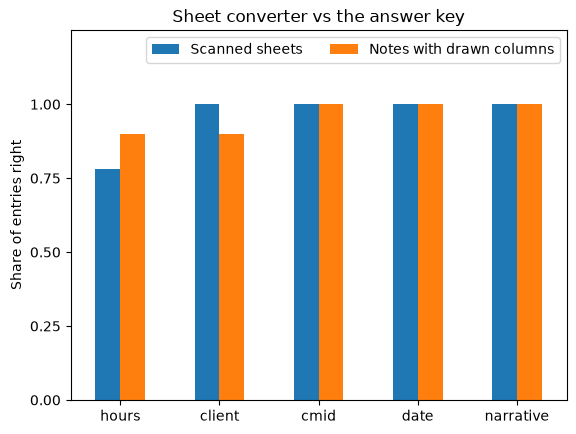

In [7]:
summary.plot.bar(rot=0)
plt.ylim(0, 1.25)
plt.yticks([0, 0.25, 0.5, 0.75, 1])
plt.ylabel("Share of entries right")
plt.title("Sheet converter vs the answer key")
plt.legend(title=None, loc="upper right", ncol=2)
plt.show()

- Every file splits into the right number of entries: 23 on the scanned sheets, and 7 and 3 on the two notes with drawn columns.
- CMIDs, dates, and narratives are right on every entry.
- Hours are the weak spot on the scanned sheets. On HW-04, Textract missed 7 small decimal points: 2 were fixed by dividing by 10 ("6" and "7" on one-task lines), and 5 are still wrong ("2", "3", "4", and "9 9", which are realistic or ambiguous whole numbers). On the notes, one hour is lost (".3" read as "in").
- One client on a note misses the similarity cutoff ("Pream Al" for "Dream AI"). Misreads like this are left for matching.
- The rules were written while looking at the scanned sheets and the first note. Note 7 was new to them and needed one more rule (a first line that wraps onto a second table row), so new samples are still the real test.

In [8]:
misses = graded[~right[FIELDS].all(axis=1)].join(right[FIELDS].add_suffix("_right"))
misses[["source", "sheet_id", "rows_key", "hours", "hours_key", "client", "client_key", "cmid", "cmid_key", "work_date",
        "work_date_key", "note"]]

,source,sheet_id,rows_key,hours,hours_key,client,client_key,cmid,cmid_key,work_date,work_date_key,note
15,2399_001.pdf,HW-04,1,3.0,0.3,Rat Bio -Series B,Rat Bio - Series B,NaN,NaN,2026-07-20,2026-07-20,Decimal point is small; Textract read 3. This ...
17,2399_001.pdf,HW-04,4,2.0,0.2,Firm-admin,Firm - admin,NaN,NaN,2026-07-20,2026-07-20,Textract read 2
19,2399_001.pdf,HW-04,6,4.0,0.4,Theories Fund 007,Theories Fund 007,NaN,NaN,2026-07-20,2026-07-20,Textract read 4; client name hard to read
20,2399_001.pdf,HW-04,7,99.0,0.9,Labs - - Formation,Labs - Formation,NaN,NaN,2026-07-20,2026-07-20,NaN
21,2399_001.pdf,HW-04,8,2.0,0.2,River Ventures,River Ventures,NaN,NaN,2026-07-20,2026-07-20,Textract read 2
24,mon_fri_sample.jpg,NaN,2,1.2,1.2,Pream Al,Dream AI,4599.002,4599.002,2026-09-21,2026-09-21,Client not in the synthetic firm
32,note_07.JPG,NaN,3,NaN,0.3,Firm Admin in,Firm Admin,1111.001,1111.001,2026-10-28,2026-10-28,NaN


- Every miss is an hour that lost its decimal point (5 on HW-04, 1 on note 7) or an OCR misread of a client name. None come from entries being split or merged wrong.

## 4. Flags

A wrong hour is fine as long as it is flagged, since a reviewer sees it before it's billed. The answer key lists the flags each entry should get. The risk to watch is a wrong hour with no flag.

In [9]:
flags = []
for reason in ["hours_10x", "client_copied", "date_guessed"]:
    expected = graded["expected_checks"].fillna("").str.contains(reason)
    caught = graded["check_reasons"].fillna("").str.contains(reason)
    flags.append({"reason": reason, "expected": expected.sum(), "caught": (expected & caught).sum(),
                  "extra": (caught & ~expected).sum()})
pd.DataFrame(flags)

,reason,expected,caught,extra
0,hours_10x,8,8,0
1,client_copied,1,1,0
2,date_guessed,13,13,0


In [10]:
wrong_hours = graded[~right["hours"]]
unflagged = wrong_hours[wrong_hours["check_reasons"].fillna("") == ""]
print(f"{len(wrong_hours)} wrong hours | {len(unflagged)} with no flag")
wrong_hours[["source", "sheet_id", "rows_key", "hours_read", "hours", "hours_key", "check_reasons"]]

6 wrong hours | 0 with no flag


,source,sheet_id,rows_key,hours_read,hours,hours_key,check_reasons
15,2399_001.pdf,HW-04,1,3,3.0,0.3,hours_10x; date_guessed
17,2399_001.pdf,HW-04,4,2,2.0,0.2,low_conf; hours_10x; date_guessed
19,2399_001.pdf,HW-04,6,4,4.0,0.4,hours_10x; date_guessed
20,2399_001.pdf,HW-04,7,9 9,99.0,0.9,low_conf; hours_10x; date_guessed
21,2399_001.pdf,HW-04,8,2,2.0,0.2,low_conf; hours_10x; date_guessed
32,note_07.JPG,NaN,3,NaN,NaN,0.3,no_hours


- Every wrong hour is flagged: the 5 on HW-04 for a missing decimal, and the one on note 7 as missing. The 2 corrected hours are flagged too, so a reviewer sees what was read. None would be billed without a reviewer seeing it first.
- The copied client (the drawn arrow on HW-02) and all 13 dates taken from Week of are flagged, with no extra flags.
- One of the 8 hours flagged for a missing decimal is actually right: HW-02's "3" really is 3.0 hours. A reviewer confirms it, which is the expected cost of this check.

## Findings

### Results
- **Splitting:** every file has the right number of entries (33 across the 4 sheets and 2 notes with drawn columns).
- **Fields:** CMID, date, and narrative right on every entry, and the client close to what was written on all but one OCR misread.
- **Hours:** 6 of 33 wrong, all from decimal points Textract missed, and all 6 flagged for review. Dividing implausibly high whole numbers by 10 fixed 2 more.
- **Drawn columns:** notes with columns drawn on them read as well as the printed form.

### Tradeoffs
- The no-decimal-point check flags some hours that are right (a true "3" for 3.0 hours), in exchange for catching every dropped decimal. Dividing by 10 only happens at 5 or more, where a whole number is rare, since a wrong guess would bill ten times too little. A reviewer confirming a few extra hours is cheaper than a client billed ten times too much.
- Merging every row without hours into the entry above is simple and matched the sample sheets, but a real entry written without hours would be merged by mistake. It still shows up with its text, so a reviewer can split it.
- Client names are passed along as written. Matching already scores misspelled names against the firm's client list, so correcting them here would duplicate that work and could hide what was actually written.

### Limitations
- Four sheets and two notes with drawn columns, from a handful of writers. The rules fit these samples, and new samples will likely need new rules.
- The answer key was typed from the scans by hand, so a few readings of messy handwriting are judgment calls (noted in its `note` column).
- One converter covers forms with a printed header and notes without one, but only one headerless note has been tested.

### Next steps
- Photograph more notes, with and without drawn columns, and add them to the answer key.
- Run the converted entries through matching's `decide()` and compare with the intended entries (notebook 03).